# Jobs and Employment in Technology and Computers

Created: 06 NOV 2026

## Summary

Provide machine learning predictions relating to jobs and employment in technology and computers utilising a large set of survey data.

### Problem Statement

The problem is that job seekers are generally distressed, being under both time and financial pressures to find a job. Job seekers are also the target of a great deal of marketing, which offers "common sense" jobseeker advice which may or may not be objectively true.

This project seeks to address that problem by providing a clear and objective method for evaluating jobs and jobseekers. Having such a tool, jobseekers can make a more well informed determination regarding their own prospects in the job market.


### Data Import

In [5]:
data_2025 = "https://github.com/StackExchange/Survey/raw/refs/heads/main/packages/archive/2025/results.csv"

!wget $data_2025 -O stack-overflow-survey-data-2025.csv

--2026-11-06 15:45:53--  https://github.com/StackExchange/Survey/raw/refs/heads/main/packages/archive/2025/results.csv
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/results.csv [following]
--2026-11-06 15:45:54--  https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/results.csv
Resolving media.githubusercontent.com (media.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to media.githubusercontent.com (media.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 140893245 (134M) [text/plain]
Saving to: ‘stack-overflow-survey-data-2025.csv’

stack-overflow-surv 100%[===================>] 134.37M  40.9MB/s    in

In [6]:
data_2024 = "https://github.com/StackExchange/Survey/raw/refs/heads/main/packages/archive/2024/results.csv"

!wget $data_2024 -O stack-overflow-survey-data-2024.csv

--2026-11-06 15:46:04--  https://github.com/StackExchange/Survey/raw/refs/heads/main/packages/archive/2024/results.csv
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2024/results.csv [following]
--2026-11-06 15:46:05--  https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2024/results.csv
Resolving media.githubusercontent.com (media.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.109.133, ...
Connecting to media.githubusercontent.com (media.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/plain]
Saving to: ‘stack-overflow-survey-data-2024.csv’

stack-overflow-surv 100%[===================>] 152.13M  34.9MB/s    in

In [7]:
data_2023 = "https://github.com/StackExchange/Survey/raw/refs/heads/main/packages/archive/2023/results.csv"

!wget $data_2023 -O stack-overflow-survey-data-2023.csv

--2026-11-06 15:46:12--  https://github.com/StackExchange/Survey/raw/refs/heads/main/packages/archive/2023/results.csv
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2023/results.csv [following]
--2026-11-06 15:46:13--  https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2023/results.csv
Resolving media.githubusercontent.com (media.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to media.githubusercontent.com (media.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 158626799 (151M) [text/plain]
Saving to: ‘stack-overflow-survey-data-2023.csv’

stack-overflow-surv 100%[===================>] 151.28M  41.5MB/s    in

In [11]:
# ONE TIME ONLY

!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 52.6 MB/s  0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 84.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]━━━━ 1/2 [pandas]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


## EDA

### IMPORTANT

`sklearn` is deprecated. Use `scikit-learn` instead.

In [16]:
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 60.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 63.8 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]0m 5/6 [scikit-learn]]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np

In [2]:
df_2025 = pd.read_csv('stack-overflow-survey-data-2025.csv')

/tmp/ipykernel_3267/167720247.py:1: DtypeWarning: Columns (56: JobSatPoints_15_TEXT, 74: DatabaseHaveEntry, 92: DevEnvHaveEntry, 97: SOTagsHaveEntry, 98: SOTagsWant Entry, 105: OfficeStackWantEntry, 109: CommPlatformHaveEntr, 110: CommPlatformWantEntr, 132: SO_Actions_15_TEXT, 162: AIAgentOrchestration, 165: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  df_2025 = pd.read_csv('stack-overflow-survey-data-2025.csv')


In [3]:
full_cols = df_2025.columns.to_list()

In [4]:
df_2024 = pd.read_csv('stack-overflow-survey-data-2024.csv')
df_2023 = pd.read_csv('stack-overflow-survey-data-2023.csv')

In [29]:
import os
os.listdir()

['.gitignore',
 'midterm-project',
 'capstone-1',
 'capstone-2',
 'README.md',
 '.git',
 '.ipynb_checkpoints',
 'LICENSE']

In [33]:
print(df_2025.columns)
print('----------')
print(df_2024.columns)
print('----------')
print(df_2023.columns)

Index(['ResponseId', 'MainBranch', 'Age', 'EdLevel', 'Employment',
       'EmploymentAddl', 'WorkExp', 'LearnCodeChoose', 'LearnCode',
       'LearnCodeAI',
       ...
       'AIAgentOrchestration', 'AIAgentOrchWrite', 'AIAgentObserveSecure',
       'AIAgentObsWrite', 'AIAgentExternal', 'AIAgentExtWrite', 'AIHuman',
       'AIOpen', 'ConvertedCompYearly', 'JobSat'],
      dtype='str', length=172)
----------
Index(['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check',
       'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline',
       ...
       'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9',
       'JobSatPoints_10', 'JobSatPoints_11', 'SurveyLength', 'SurveyEase',
       'ConvertedCompYearly', 'JobSat'],
      dtype='str', length=114)
----------
Index(['ResponseId', 'Q120', 'MainBranch', 'Age', 'Employment', 'RemoteWork',
       'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline',
       'LearnCodeCoursesCert', 'YearsCode', 

In [34]:
df_2025.describe()

,ResponseId,WorkExp,YearsCode,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,...,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,ConvertedCompYearly,JobSat
count,49191.000000,42893.000000,43042.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,...,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,2.394700e+04,26670.000000
mean,24596.000000,13.367403,16.570861,7.867352,4.104211,4.110271,5.678193,4.119388,5.225990,6.477387,...,5.718355,4.561767,4.790861,5.199657,5.676314,4.984653,7.099505,10.079284,1.017615e+05,7.201950
std,14200.362883,10.800117,11.787610,2.397432,2.275821,2.329536,2.398084,2.437945,2.801045,2.331468,...,2.628016,3.070548,2.643177,2.563562,2.310659,2.490095,2.469394,1.940928,4.617569e+05,1.997245
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,0.000000
25%,12298.500000,5.000000,8.000000,7.000000,2.000000,2.000000,4.000000,2.000000,3.000000,5.000000,...,3.000000,1.000000,3.000000,3.000000,4.000000,3.000000,6.000000,10.000000,3.817100e+04,6.000000
50%,24596.000000,10.000000,14.000000,9.000000,4.000000,4.000000,6.000000,4.000000,5.000000,7.000000,...,6.000000,4.000000,5.000000,5.000000,6.000000,5.000000,8.000000,10.000000,7.532000e+04,8.000000
75%,36893.500000,20.000000,24.000000,9.000000,6.000000,6.000000,8.000000,6.000000,8.000000,8.000000,...,8.000000,7.000000,7.000000,7.000000,7.000000,7.000000,9.000000,10.000000,1.205960e+05,8.000000
max,49191.000000,100.000000,100.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,...,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,5.000000e+07,10.000000


In [35]:
df_2024.describe()

,ResponseId,CompTotal,WorkExp,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,ConvertedCompYearly,JobSat
count,65437.000000,3.374000e+04,29658.000000,29324.000000,29393.000000,29411.000000,29450.000000,29448.00000,29456.000000,29456.000000,29450.000000,29445.000000,2.343500e+04,29126.000000
mean,32719.000000,2.963841e+145,11.466957,18.581094,7.522140,10.060857,24.343232,22.96522,20.278165,16.169432,10.955713,9.953948,8.615529e+04,6.935041
std,18890.179119,5.444117e+147,9.168709,25.966221,18.422661,21.833836,27.089360,27.01774,26.108110,24.845032,22.906263,21.775652,1.867570e+05,2.088259
min,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000
25%,16360.000000,6.000000e+04,4.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,3.271200e+04,6.000000
50%,32719.000000,1.100000e+05,9.000000,10.000000,0.000000,0.000000,20.000000,15.00000,10.000000,5.000000,0.000000,0.000000,6.500000e+04,7.000000
75%,49078.000000,2.500000e+05,16.000000,22.000000,5.000000,10.000000,30.000000,30.00000,25.000000,20.000000,10.000000,10.000000,1.079715e+05,8.000000
max,65437.000000,1.000000e+150,50.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,1.625660e+07,10.000000


In [36]:
df_2023.describe()

,ResponseId,CompTotal,WorkExp,ConvertedCompYearly
count,89184.000000,4.822500e+04,43579.000000,4.801900e+04
mean,44592.500000,1.036807e+42,11.405126,1.031101e+05
std,25745.347541,2.276847e+44,9.051989,6.814188e+05
min,1.000000,0.000000e+00,0.000000,1.000000e+00
25%,22296.750000,6.300000e+04,5.000000,4.390700e+04
50%,44592.500000,1.150000e+05,9.000000,7.496300e+04
75%,66888.250000,2.300000e+05,16.000000,1.216410e+05
max,89184.000000,5.000000e+46,50.000000,7.435143e+07


Clear trend: Each year, fewer and fewer people are taking the survey, while each year, the survey has more and more questions

In [12]:
df_2025.columns.size

172

In [13]:
df_2024.columns.size

114

In [14]:
df_2023.columns.size

84

In [16]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 66.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 65.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 44.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 63.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]er]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [18]:
!pip install seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

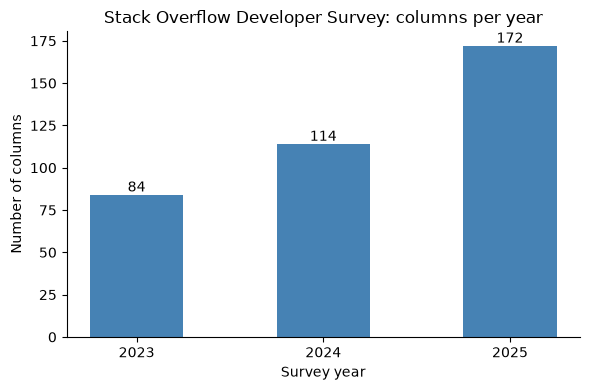

In [20]:
years = ['2023', '2024', '2025']
n_columns = [df_2023.columns.size, df_2024.columns.size, df_2025.columns.size]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(years, n_columns, width=0.5, color='steelblue')
ax.bar_label(bars)                      # print the value on top of each bar
ax.set_xlabel('Survey year')
ax.set_ylabel('Number of columns')
ax.set_title('Stack Overflow Developer Survey: columns per year')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

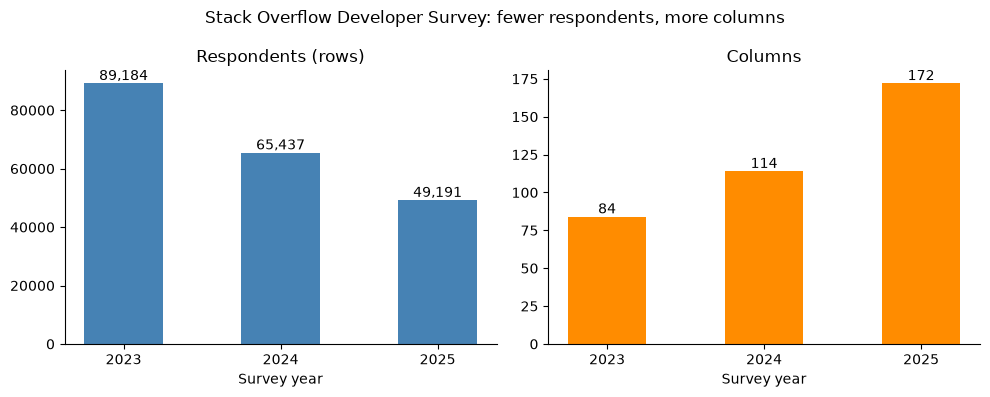

In [21]:
dfs = {'2023': df_2023, '2024': df_2024, '2025': df_2025}
years = list(dfs)
n_rows = [len(d) for d in dfs.values()]
n_cols = [d.columns.size for d in dfs.values()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

b1 = ax1.bar(years, n_rows, width=0.5, color='steelblue')
ax1.bar_label(b1, fmt='{:,.0f}')
ax1.set_title('Respondents (rows)')

b2 = ax2.bar(years, n_cols, width=0.5, color='darkorange')
ax2.bar_label(b2)
ax2.set_title('Columns')

for ax in (ax1, ax2):
    ax.set_xlabel('Survey year')
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Stack Overflow Developer Survey: fewer respondents, more columns')
plt.tight_layout()
plt.show()

In [23]:
### Harmonisation

Three data sets into one

SyntaxError: invalid syntax (2622086565.py, line 3)

In [5]:
from harmonise import harmonise

In [6]:
# Make one large dataset from three
df = pd.concat([harmonise(df_2023, 2023),
                harmonise(df_2024, 2024),
                harmonise(df_2025, 2025)], ignore_index=True)

In [7]:
# Modelling subset: Working developers with plausible pay
model_df = df[
    df['ConvertedCompYearly'].between(5_000, 500_000)
    & df['Employment'].isin(['Employed',
                             'Independent contractor, freelancer, or self-employed'])
    & (df['MainBranch'] == 'I am a developer by profession')
].copy()
model_df['log_comp'] = np.log1p(model_df['ConvertedCompYearly'])

In [9]:
# Feature-importance analysis for important features

mask = (
    model_df['ConvertedCompYearly'].between(5_000, 500_000)
    & model_df['Employment'].isin(['Employed',
                             'Independent contractor, freelancer, or self-employed'])
    & (model_df['MainBranch'] == 'I am a developer by profession')
)
d = model_df[mask].copy()
d['log_comp'] = np.log1p(d['ConvertedCompYearly'])
 
categorical = ['Country', 'Age', 'EdLevel', 'Employment', 'DevRole', 'OrgSize',
               'RemoteWork', 'ICorPM', 'Industry', 'AISelect']
numerical = ['WorkExp', 'YearsCode']
lang_cols = [c for c in d.columns if c.startswith('lang_')]
print(f'{len(d):,} rows')

35,748 rows


In [10]:
# Median salary by category, relative to the overall median
# The regression equivalent of the lectute's "risk ratio" tables

global_median = d['ConvertedCompYearly'].median()
for col in ['Country', 'RemoteWork', 'ICorPM', 'Employment', 'OrgSize', 'DevRole']:
    t = d.groupby(col)['ConvertedCompYearly'].agg(['median', 'count'])
    t['ratio'] = (t['median'] / global_median).round(2)
    t['median'] = t['median'].round(0)
    display(t.sort_values('median', ascending=False))

,median,count,ratio
Country,,,
Luxembourg,104413.0,75,1.53
Ireland,104413.0,495,1.53
Denmark,94380.0,853,1.39
United Kingdom of Great Britain and Northern Ireland,86897.0,5734,1.28
Cyprus,76837.0,88,1.13
Germany,76570.0,7023,1.12
Netherlands,74963.0,2261,1.10
Austria,71750.0,1000,1.05
Finland,69609.0,711,1.02


,median,count,ratio
RemoteWork,,,
Remote,74963.0,11903,1.10
Hybrid,66128.0,18959,0.97
In-person,52474.0,3989,0.77


,median,count,ratio
ICorPM,,,
People manager,81210.0,3086,1.19
Individual contributor,65325.0,22980,0.96


,median,count,ratio
Employment,,,
"Independent contractor, freelancer, or self-employed",85672.0,4284,1.26
Employed,65691.0,31464,0.96


,median,count,ratio
OrgSize,,,
"Just me - I am a freelancer, sole proprietor, etc.",80555.0,1442,1.18
"10,000 or more employees",80317.0,3532,1.18
"5,000 to 9,999 employees",74978.0,1272,1.10
"1,000 to 4,999 employees",70679.0,4172,1.04
500 to 999 employees,69609.0,2483,1.02
100 to 499 employees,68740.0,7139,1.01
20 to 99 employees,64254.0,8260,0.94
Less than 20 employees,57423.0,6232,0.84


,median,count,ratio
DevRole,,,
Executive / founder,101735.0,459,1.49
Manager,93104.0,997,1.37
Architect,92812.0,665,1.36
Security,84601.0,92,1.24
DevOps / cloud / SRE,77104.0,1320,1.13
Other,77104.0,1127,1.13
Data engineer,73338.0,744,1.08
"Developer, back-end",71962.0,7961,1.06
"Developer, mobile",71892.0,1267,1.06


In [12]:
# Numerical features: Correlation with log salary

d[numerical + ['log_comp']].corr()['log_comp'].round(3)

WorkExp      0.355
YearsCode    0.347
log_comp     1.000
Name: log_comp, dtype: float64

In [17]:
# Mutual information with log salary (all features)
# Note: MI tends to favour high-cardinality features such as Country.

from sklearn.feature_selection import mutual_info_regression
 
X_mi = d[categorical + numerical + lang_cols].copy()
for c in categorical:
    X_mi[c] = X_mi[c].astype('category').cat.codes      # missing -> -1
X_mi = X_mi.fillna(-1)
discrete = [c in categorical or c in lang_cols for c in X_mi.columns]
 
mi = mutual_info_regression(X_mi, d['log_comp'],
                            discrete_features=discrete, random_state=1)
pd.Series(mi, index=X_mi.columns).sort_values(ascending=False).round(4).head(15)

Country          0.8548
Industry         0.3354
WorkExp          0.1508
YearsCode        0.1171
Age              0.1044
RemoteWork       0.0797
OrgSize          0.0725
DevRole          0.0553
AISelect         0.0487
Employment       0.0399
ICorPM           0.0382
EdLevel          0.0293
lang_PHP         0.0248
lang_Java        0.0184
lang_HTML/CSS    0.0182
dtype: float64

R2 (log) = 0.467   MAE (USD) = 20,979


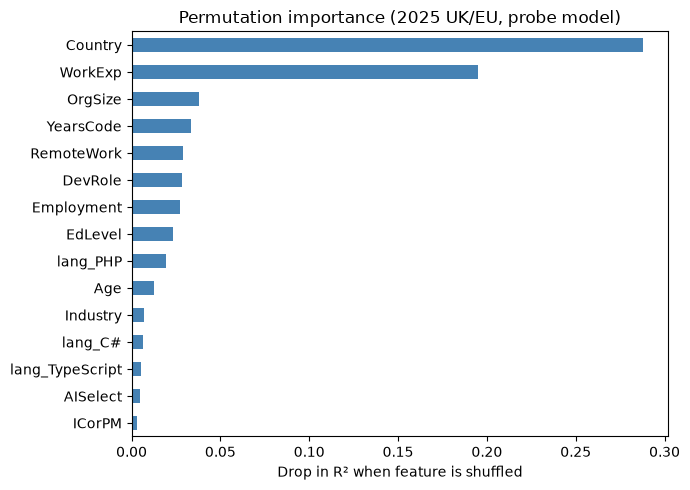

In [21]:
# Probe model + permutation importance
# A quick, untuned model used only to rank features
# Not the final model.

from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error
 
X = d[categorical + numerical + lang_cols].copy()
for c in categorical:
    X[c] = X[c].astype('category')
y = d['log_comp']
 
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=1)
probe = HistGradientBoostingRegressor(categorical_features='from_dtype',
                                      random_state=1).fit(X_tr, y_tr)
pred = probe.predict(X_te)
print(f'R2 (log) = {r2_score(y_te, pred):.3f}   '
      f'MAE (USD) = {mean_absolute_error(np.expm1(y_te), np.expm1(pred)):,.0f}')
 
pi = permutation_importance(probe, X_te, y_te, n_repeats=5, random_state=1)
importance = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
 
ax = importance.head(15).sort_values().plot.barh(figsize=(7, 5), color='steelblue')
ax.set_xlabel('Drop in R² when feature is shuffled')
ax.set_title('Permutation importance (2025 UK/EU, probe model)')
plt.tight_layout()
plt.show()

In [22]:
# Text normalisation
# Apply AFTER harmonise, and identically in predict.py

def normalise_text(df):
    """Lower-case and replace spaces with underscores in column names and in
    all text values. Keeps symbols, so lang_C# and lang_C++ stay distinct."""
    df = df.copy()
    df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
    for c in df.select_dtypes(include=['object', 'string']).columns:
        df[c] = df[c].str.strip().str.lower().str.replace(' ', '_')